# Expert pruning: zero-shot loss vs. experts pruned per layer

Part of plan.md step 2.3 -- the first real expert-pruning experiment,
mirroring `05_depth_pruning_sweep.ipynb`'s methodology on a different axis.
`bonsai.pruning.experts.prune_experts` actually removes experts from
`Qwen3MoeExperts`/`Qwen3MoeTopKRouter` (not a temporary swap) and measures
the resulting zero-shot loss (`bonsai.importance.depth.mean_loss`) on
`Qwen3-30B-A3B-Base`, at eight uniform per-layer counts (8, 16, 32, 48, 64,
80, 96, 112 of 128 experts, pruned the same amount in every one of the 48
sparse layers), under two selection strategies:

- **greedy**: prune the $n$ lowest-`expert_importance`-scoring experts per
  layer (the gate-weighted output-norm score from
  `03_importance_scores.ipynb`'s already-saved `importance-scores.pt`),
  with the three known Super Experts (layer 1/expert 68, layer 2/expert 92,
  layer 3/expert 82; arXiv 2507.23279) exempted from the ranking entirely
  -- `select_experts_to_prune`'s `protected` argument -- per plan.md 2.3's
  decision to guard them before ranking, not just check afterward.
- **random**: prune $n$ random experts per layer (same protected
  exemption), 3 seeds -- the control greedy selection has to beat.

Plus one candidate outside the count sweep: **super_experts_only** -- prune
*just* the three known Super Experts, nothing else, to reproduce arXiv
2507.23279's own finding (deleting them alone measured a WikiText-2 PPL
jump from 8.70 to 59.86) directly in this pipeline's own loss metric -- the
regression test plan.md 1.3 already promised to reuse.

Each candidate costs exactly one forward pass over 32 fresh calibration
samples (seed=1, disjoint draw from the same pinned calibration shard used
everywhere else). The actual GPU orchestration lives in a throwaway script
(`scratch_expert_pruning_sweep.py`, run once on a rented H100 and deleted
after, same convention as the depth sweep) -- this notebook only loads its
saved output and visualizes it.

In [1]:
import torch

RUN_DIR = "../runs/20260919T222436Z-a1773c5-expert-pruning-sweep"
data = torch.load(f"{RUN_DIR}/expert-pruning-sweep.pt", weights_only=False)

results = data["results"]
counts = data["counts"]
baseline_loss = next(r["loss"] for r in results if r["strategy"] == "baseline")
super_experts_loss = next(r["loss"] for r in results if r["strategy"] == "super_experts_only")

print(
    f"{data['num_layers']} layers, {data['num_experts']} experts/layer, "
    f"{data['num_samples']} calibration samples, mean length {data['mean_length']:.0f} tokens"
)
print(f"protected (Super Experts): {data['protected']}")
print(f"counts swept (per layer, uniform): {counts}")
print(f"baseline (0 pruned) loss: {baseline_loss:.4f}")
print(f"super_experts_only loss: {super_experts_loss:.4f}")
print(f"{len(results)} total candidates evaluated")

48 layers, 128 experts/layer, 32 calibration samples, mean length 176 tokens
protected (Super Experts): {1: [68], 2: [92], 3: [82]}
counts swept (per layer, uniform): [8, 16, 32, 48, 64, 80, 96, 112]
baseline (0 pruned) loss: 0.9670
super_experts_only loss: 1.4675
34 total candidates evaluated


## The main result

One line for greedy selection, random shown as a mean line plus its
min-max band across seeds, plus a dashed reference for the
super-experts-only candidate -- y-axis is log-scale since loss spans more
than 5x across the sweep.

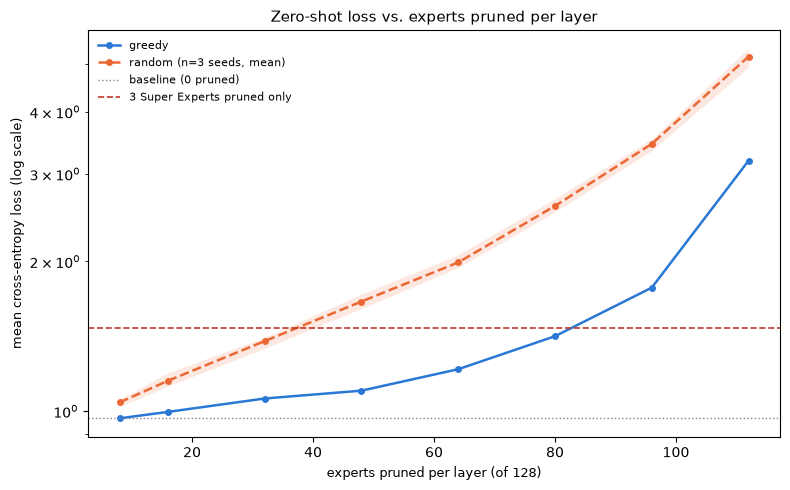

In [2]:
from bonsai.pruning.viz import plot_pruning_sweep

greedy_losses = [
    next(r["loss"] for r in results if r["strategy"] == "greedy" and r["n"] == n) for n in counts
]
random_losses = [
    [r["loss"] for r in results if r["strategy"] == "random" and r["n"] == n] for n in counts
]

fig = plot_pruning_sweep(
    counts,
    {"greedy": greedy_losses},
    random_losses,
    baseline_loss=baseline_loss,
    title="Zero-shot loss vs. experts pruned per layer",
    xlabel="experts pruned per layer (of 128)",
    extra_hlines={"3 Super Experts pruned only": super_experts_loss},
)
fig.savefig(f"{RUN_DIR}/expert_pruning_sweep.png", dpi=150)
fig.savefig(f"{RUN_DIR}/expert_pruning_sweep.pdf")

## Numbers behind the plot

Loss relative to baseline, as a percentage increase, alongside the total
number of experts actually removed from the model at each count (48 sparse
layers x $n$ per layer).

In [3]:
import numpy as np

random_arr = np.array(random_losses)
random_mean = random_arr.mean(axis=1)

header = f"{'n':>4}  {'total pruned':>12}  {'greedy':>10}  {'random (mean)':>14}"
print(header)
print("-" * len(header))
for i, n in enumerate(counts):
    g_rel = greedy_losses[i] / baseline_loss - 1
    r_rel = random_mean[i] / baseline_loss - 1
    print(f"{n:>4}  {n * data['num_layers']:>12}  {g_rel:>+10.1%}  {r_rel:>+14.1%}")

   n  total pruned      greedy   random (mean)
----------------------------------------------
   8           384       -0.0%           +7.7%
  16           768       +3.0%          +19.0%
  32          1536       +9.6%          +43.0%
  48          2304      +13.7%          +71.8%
  64          3072      +25.5%         +105.9%
  80          3840      +46.3%         +167.4%
  96          4608      +83.2%         +256.4%
 112          5376     +229.7%         +434.0%


## Three experts vs. thousands: the Super Experts regression test

The starkest finding in this sweep isn't on the main curve at all. Pruning
*only* the three known Super Experts -- 3 experts total, out of 6,144 in the
model -- costs more zero-shot loss (+51.8%) than greedy-pruning 8, 16, or
even 32 ordinary experts per layer (384, 768, and 1,536 experts removed,
respectively; the last of those three still lands at only +9.6%). Greedy
selection doesn't cross the super-experts-only line until somewhere between
$n=80$ and $n=96$ per layer -- 3,840 to 4,608 total experts removed, roughly
1,300-1,500x as many as the three Super Experts alone. This reproduces arXiv
2507.23279's own claim (deleting them alone caused a WikiText-2 PPL jump
from 8.70 to 59.86) directly in this pipeline's own loss metric and on this
project's own TypeScript calibration data, not just by citation -- and it's
the concrete justification for exempting them from the ranking
(`select_experts_to_prune`'s `protected` argument) rather than trusting the
score alone to never rank them low, however unlikely that already looked
from 1.3's sanity check.

## Summary

- **Greedy selection clearly beats random at every count**, though the gap
  is a smaller multiple than depth pruning's (roughly 2-5x in relative-loss
  terms here, vs. close to an order of magnitude for layers) -- expert
  redundancy is real but less winner-take-all than layer redundancy on this
  model, consistent with 128 experts/layer offering many more substitutable
  choices than 48 layers do.
- **Pruning is nearly free up to a point**: $n=8$ per layer (384 experts
  total) lands at the *same* loss as the unpruned baseline; the curve only
  starts bending noticeably past $n=48$-64 (2,304-3,072 experts).
- **Three specific experts matter more than thousands of ordinary ones** --
  the super-experts-only regression test above is the clearest evidence yet,
  in this project's own pipeline, for why 1.3/2.3's outlier guard exists.
- **Loss grows steeply past $n=96$**: the jump from $n=96$ to $n=112$
  (+83.2% to +229.7% for greedy) is much sharper than any earlier step,
  suggesting the model runs out of true redundancy somewhere in that range
  -- consistent with `num_experts_per_tok=8` meaning every layer needs a
  reasonably diverse pool to route into, not just its single best expert.

**What this means for Phase 2 going forward:** the greedy, protected-guard
criterion (`expert_importance` + `select_experts_to_prune`'s `protected`
exemption) is the working choice for expert pruning, validated both by
beating random at every count and by the Super Experts regression test
landing exactly where the guard predicts it should. The right target count
for this project's final pruned model is still open -- pending how expert
pruning combines with depth pruning in 2.4, per plan.md's existing note that
axis rankings can shift after that combination and its follow-on retraining.